In [ ]:
#!pip install openpyxl

In [1]:
# import common libs
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
# import seaborn as sns


In [2]:
# Import the required classes
from capbet.evaluators.molgenevalsimple import MoleculeSetEvaluatorSimple
from capbet.core.wrappers.molecule import Molecule, MoleculeSet


In [10]:
df_1 = pd.read_csv("../data/interim/molmim/unguided/molmmim_BCS-CN20332_LogP_sim03_100p_100m.csv", sep=";")
df_1.sort_values("LogP", ascending=False, inplace=True)

In [11]:
df_1.head()

,smiles,score,LogP,QED
58,COC(=O)C1=C(C)NC2(CCCC2)[C@H]1c1cccc(Cl)c1F,0.367772,3.9257,0.838155
79,COC[C@H](NC(=O)c1csc(Br)n1)c1ccc(F)cc1,0.945094,3.1622,0.892395
99,COC[C@H](NC(=O)c1csc(Br)n1)c1ccc(F)cc1,0.945094,3.1622,0.892395
18,COC(=O)CCNC(=O)C1(C)CC(N[C@@H]2CC(C)(C)Cc3cccc...,0.430794,3.1377,0.753055
59,COC(=O)CCNC(=O)C1(C)CCN([C@H]2CCc3cc(Cl)ccc32)CC1,0.705226,3.1087,0.799648


In [14]:
df_2 = pd.read_csv("../data/interim/molmim/guided/molmmim-Guided_BCS-CN20332_batch1_n100_Logp.csv", sep=";")
df_2.sort_values("LogP", ascending=False, inplace=True)
df_2.head()

,valid_smiles,LogP,QED
0,COC(=O)CCNC(=O)c1ccc(-c2cccs2)cc1,2.70800,0.861041
1,COC(=O)CCNC(=O)c1ccc(-n2ccc(C(F)(F)F)n2)cc1,2.18400,0.846314
2,COC(=O)CCNC(=O)c1ccc(NC(=O)c2cc(C)ccc2C)cc1,2.84864,0.781427
3,COC(=O)CCNC(=O)c1ccc(NC(=O)c2ccc(C)cc2)cc1,2.54022,0.791604
4,COC(=O)CCNC(=O)c1ccc(CNC(=O)Nc2cccc(N)c2)cc1,1.88340,0.437766


In [20]:
df = pd.read_excel("/home/ec2-user/SageMaker/data/raw/df_ICA_bionemo_eval_20250219.xlsx")
df.head()

,SUBSTANCE,SUBSTANCE_KEYS,std_smiles,AI_H,HSEC,AVEFA_PO_PROF,Lolium_PO_PROF,TRZAX_PO_PROF,AMAPA_PO_SEC_PROF,LOGD_neutral,LOGD_acid,SOL_mgL,SIP
0,BCS-DS23822,['BCS-DS23822'],C=C[C@]1(C(=O)N[C@H]2CO[C@@H](C(=O)O)C2)CC(c2c...,318.0,317.0,NaN,NaN,NaN,NaN,0.89,1.93,3050.00,NaN
1,BCS-DH85862,['BCS-DH85862'],Cc1cc(F)cc(C2=NO[C@@](C)(C(=O)N[C@H]3C=C[C@@H]...,338.0,231.0,NaN,NaN,NaN,NaN,2.72,2.80,28.30,NaN
2,BCS-CS64954,['BCS-CS64954'],COc1ccc(C2=NOC(C)(C(=O)NC3CC3)C2)cc1,0.0,0.0,NaN,NaN,NaN,NaN,1.79,1.77,68.65,NaN
3,BCS-CO63781,['BCS-CO63781'],CC1(C(=O)CCCC(=O)O)CC(c2cc(Cl)cc(Cl)c2)=NO1,120.0,92.0,NaN,NaN,NaN,NaN,1.11,2.72,1710.00,NaN
4,BCS-DC54916,['BCS-DC54916'],C=C[C@]1(C(=O)NCc2ccnc(OC)c2)CC(c2cc(F)cc(F)c2...,397.0,302.0,NaN,NaN,NaN,NaN,2.85,2.81,10.15,NaN


In [22]:

# Create sample datasets
print("\nCreating sample datasets...")

# Generated molecules (some valid, some invalid, some duplicates)
generated_smiles = df_1.smiles 

# Generated molecules (some valid, some invalid, some duplicates)
generated_smiles2 = df_2.valid_smiles 

# Reference dataset (for novelty comparison)
reference_smiles = df.std_smiles

# Input dataset (for non-identicality comparison)
input_smiles = [
    "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
]
## first Bayer Seed
#m1 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
#m1_name = "BCS-CN20332" 

## second seed
#m2 = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
#m2_name = "BCS-CE65417"



Creating sample datasets...


In [23]:

# Create MoleculeSet objects
print("Creating MoleculeSet objects...")
print("°°° DF1")
generated_set = MoleculeSet()
generated_set.add_from_smiles_list(generated_smiles)
print("°°° DF2")
generated_set2 = MoleculeSet()
generated_set2.add_from_smiles_list(generated_smiles2)
print("°°° DF-ref = Bayer")
reference_set = MoleculeSet()
reference_set.add_from_smiles_list(reference_smiles)

input_set = MoleculeSet()
input_set.add_from_smiles_list(input_smiles, ["BCS-CN20332"])


Creating MoleculeSet objects...
°°° DF1
°°° DF2
°°° DF-ref = Bayer


[13:37:02] SMILES Parse Error: unclosed ring for input: 'COC(=O)CCNC(=O)C1(C)CC2(CC(=O)N2CC[C@H]2CO)C1'
[13:37:02] SMILES Parse Error: unclosed ring for input: 'COC(=O)CCNC(=O)C1(C)CC2(CC(=O)N2CC[C@H]2CO)C1'
[13:37:02] SMILES Parse Error: unclosed ring for input: 'COC(=O)CCNC(=O)C1(C)CC2(CC(=O)N2CC[C@H](O)C2)C1'
[13:37:02] SMILES Parse Error: extra close parentheses while parsing: COC(=O)CCNC(=O)C1(C)CC2(CC(=O)[C@H]3CC[C@H](O)CC3)C2)C1
[13:37:02] SMILES Parse Error: Failed parsing SMILES 'COC(=O)CCNC(=O)C1(C)CC2(CC(=O)[C@H]3CC[C@H](O)CC3)C2)C1' for input: 'COC(=O)CCNC(=O)C1(C)CC2(CC(=O)[C@H]3CC[C@H](O)CC3)C2)C1'
[13:37:02] SMILES Parse Error: unclosed ring for input: 'COC(=O)CCNC(=O)C1=NNC(=O)C1(c2ccccc2)CC1'


In [24]:
len(generated_set)

115


Evaluating using fingerprint comparison...
MOLECULE SET EVALUATION REPORT
Comparison Method: fingerprint
Fingerprint Type: morgan
Similarity Threshold: 1
------------------------------------------------------------
Validity: 1.0000 (100.00%)
Uniqueness: 0.9892 (98.92%)
Novelty: 1.0000 (100.00%)
Effective_novelty: 0.9892 (98.92%)
Non_identicality: 1.0000 (100.00%)
------------------------------------------------------------
Total molecules: 93
Valid molecules: 93
Unique molecules: 92
Novel molecules: 92
Non-identical molecules: 93


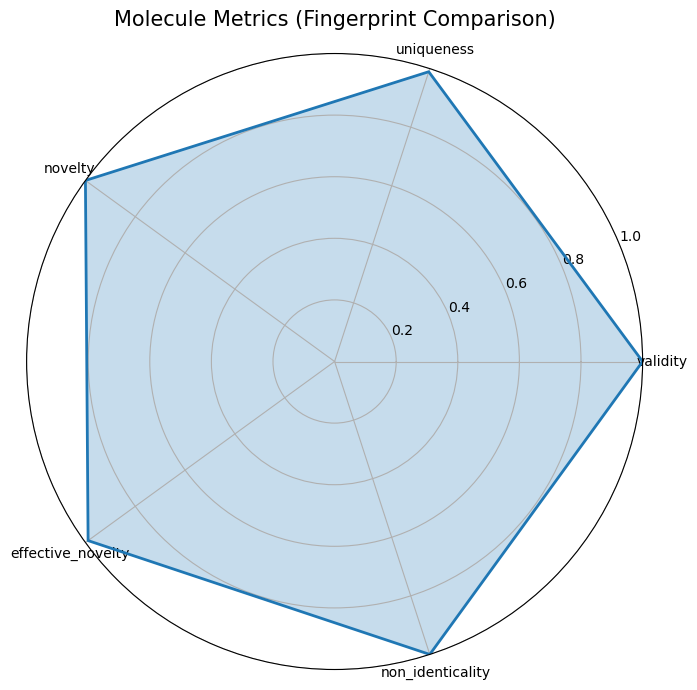

In [28]:

# Evaluate using fingerprint comparison
print("\nEvaluating using fingerprint comparison...")

fp_evaluator = MoleculeSetEvaluatorSimple(
    generated_set=generated_set2,
    reference_set=reference_set,
    input_set=input_set,
    comparison_method='fingerprint',
    fingerprint_type='morgan',
    similarity_threshold=1
)

fp_evaluator.print_report()
fp_evaluator.plot_metrics(title="Molecule Metrics (Fingerprint Comparison)", save_path="fingerprint_guided_LogP.png")
fp_evaluator.add_run("Guided LogP")

MOLECULE SET EVALUATION REPORT
Comparison Method: fingerprint
Fingerprint Type: morgan
Similarity Threshold: 1
------------------------------------------------------------
Validity: 1.0000 (100.00%)
Uniqueness: 0.6174 (61.74%)
Novelty: 1.0000 (100.00%)
Effective_novelty: 0.6174 (61.74%)
Non_identicality: 1.0000 (100.00%)
------------------------------------------------------------
Total molecules: 115
Valid molecules: 115
Unique molecules: 71
Novel molecules: 71
Non-identical molecules: 115

STATISTICS ACROSS RUNS
------------------------------------------------------------
Validity:
  mean: 1.0000
  median: 1.0000
  min: 1.0000
  max: 1.0000
  std: nan

Uniqueness:
  mean: 0.9892
  median: 0.9892
  min: 0.9892
  max: 0.9892
  std: nan

Novelty:
  mean: 1.0000
  median: 1.0000
  min: 1.0000
  max: 1.0000
  std: nan

Effective_novelty:
  mean: 0.9892
  median: 0.9892
  min: 0.9892
  max: 0.9892
  std: nan

Non_identicality:
  mean: 1.0000
  median: 1.0000
  min: 1.0000
  max: 1.0000
  s

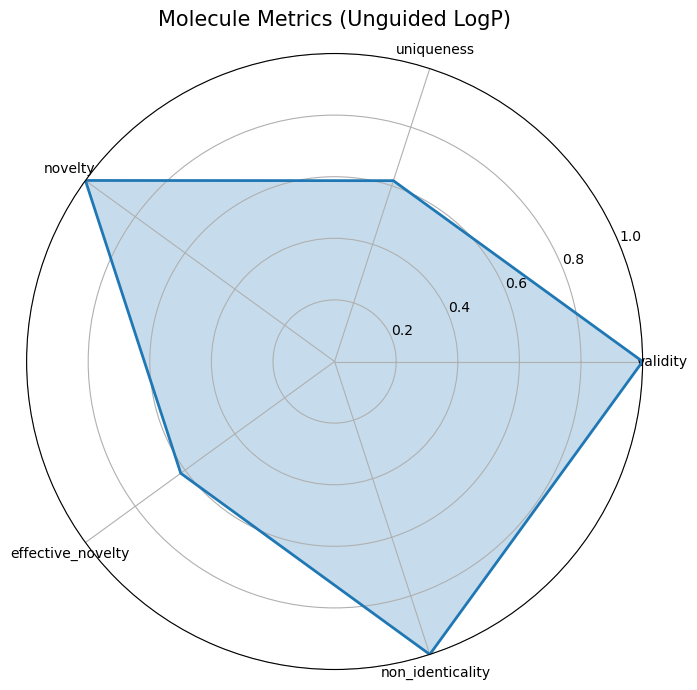

In [30]:
# Now update the evaluator with the second dataset (ref stays the same)
fp_evaluator.generated_set = generated_set  # Replace with second dataset

# Evaluate and add the first run
fp_evaluator.print_report()
fp_evaluator.plot_metrics(title="Molecule Metrics (Unguided LogP)", save_path="fingerprint_unguided_LogP.png")
fp_evaluator.add_run("Unguided LogP")



Comparing all runs...


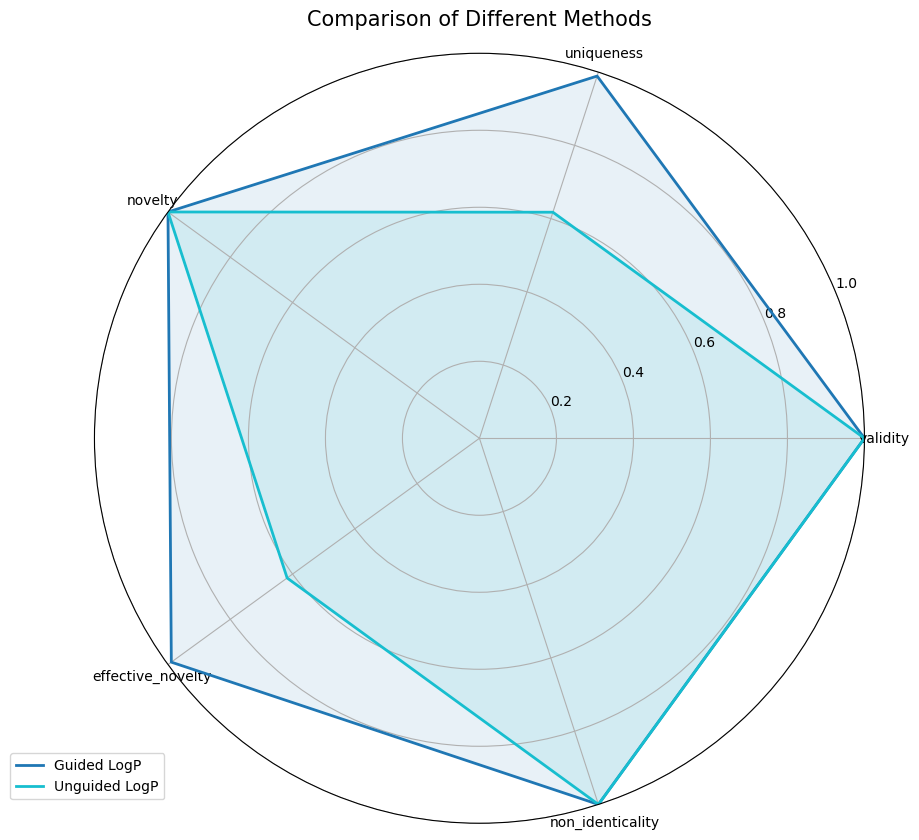

In [31]:

# Now compare all runs
print("\nComparing all runs...")
fp_evaluator.plot_multiple_runs(title="Comparison of Different Methods", save_path="method_comparison.png")